## Задание 1. Высокочастотная фильтрация на основе ядра Гаусса

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

In [2]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

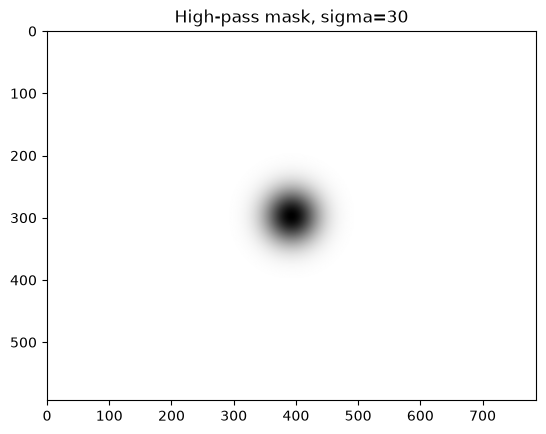

In [3]:
h, w = img.shape
X, Y = np.meshgrid(np.arange(w), np.arange(h))
cx, cy = w // 2, h // 2

sigma = 30
gauss = np.exp(-((X - cx)**2 + (Y - cy)**2) / (2 * sigma**2))
hp_mask = 1 - gauss

plt.imshow(hp_mask, cmap='gray')
plt.title(f'High-pass mask, sigma={sigma}')
plt.show()

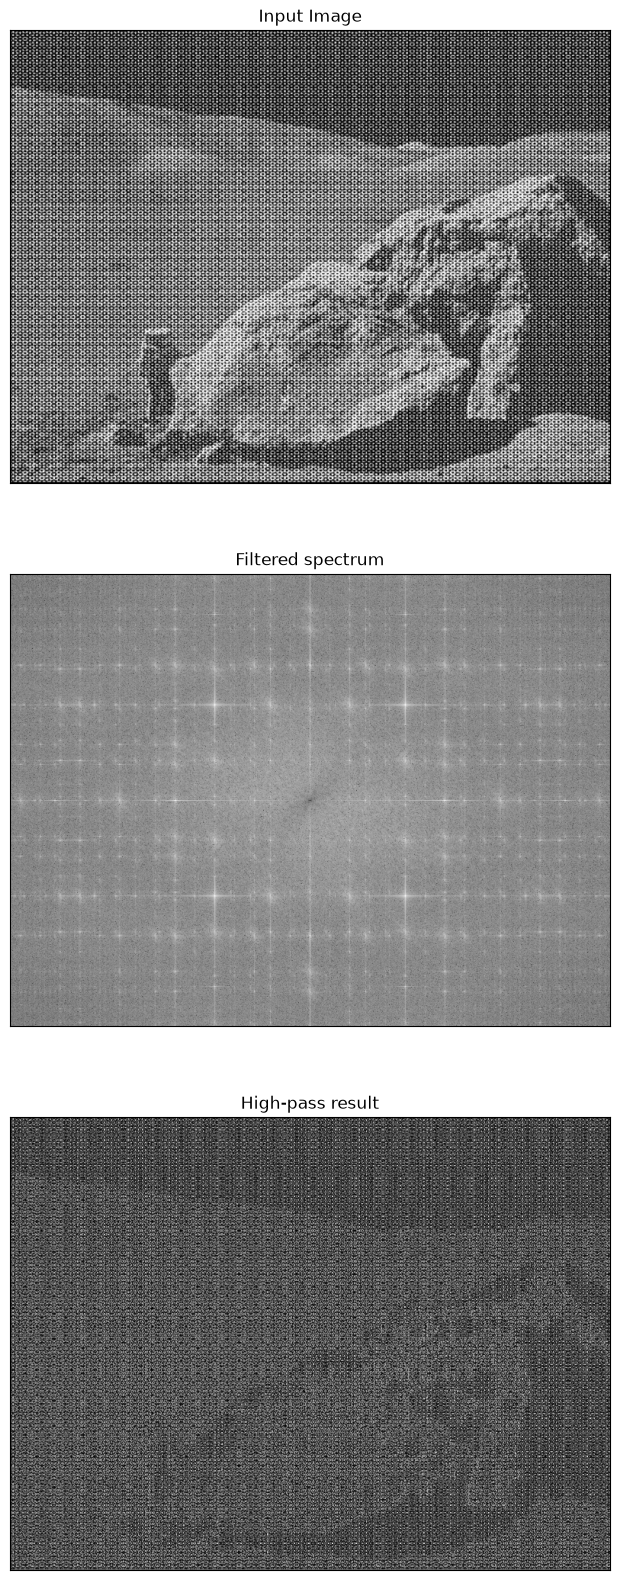

In [4]:
hp_shift = dft_shift * hp_mask[:, :, np.newaxis]

img_back = cv.idft(np.fft.ifftshift(hp_shift, axes=(0, 1)))
img_hp = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

plt.figure(figsize=(8, 20))
plt.subplot(311), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(312), plt.imshow(np.log(1 + cv.magnitude(hp_shift[:, :, 0], hp_shift[:, :, 1])), cmap='gray')
plt.title('Filtered spectrum'), plt.xticks([]), plt.yticks([])
plt.subplot(313), plt.imshow(img_hp, cmap='gray')
plt.title('High-pass result'), plt.xticks([]), plt.yticks([])
plt.show()

## Задание 2. Вычисление свёртки с помощью преобразования Фурье

In [5]:
kernel = np.ones((5, 5), np.float32) / 25

In [6]:
ref = cv.filter2D(img.astype(np.float32), -1, kernel)

In [7]:
kernel_pad = np.zeros_like(img, dtype=np.float32)
kernel_pad[:5, :5] = kernel

kernel_pad = np.roll(kernel_pad, (-2, -2), axis=(0, 1))

In [8]:
F = np.fft.fft2(img)
K = np.fft.fft2(kernel_pad)

res = np.fft.ifft2(F * K).real

Max diff (whole image): 46.9999983101489
Max diff (without 5px border): 5.7854986778238526e-05


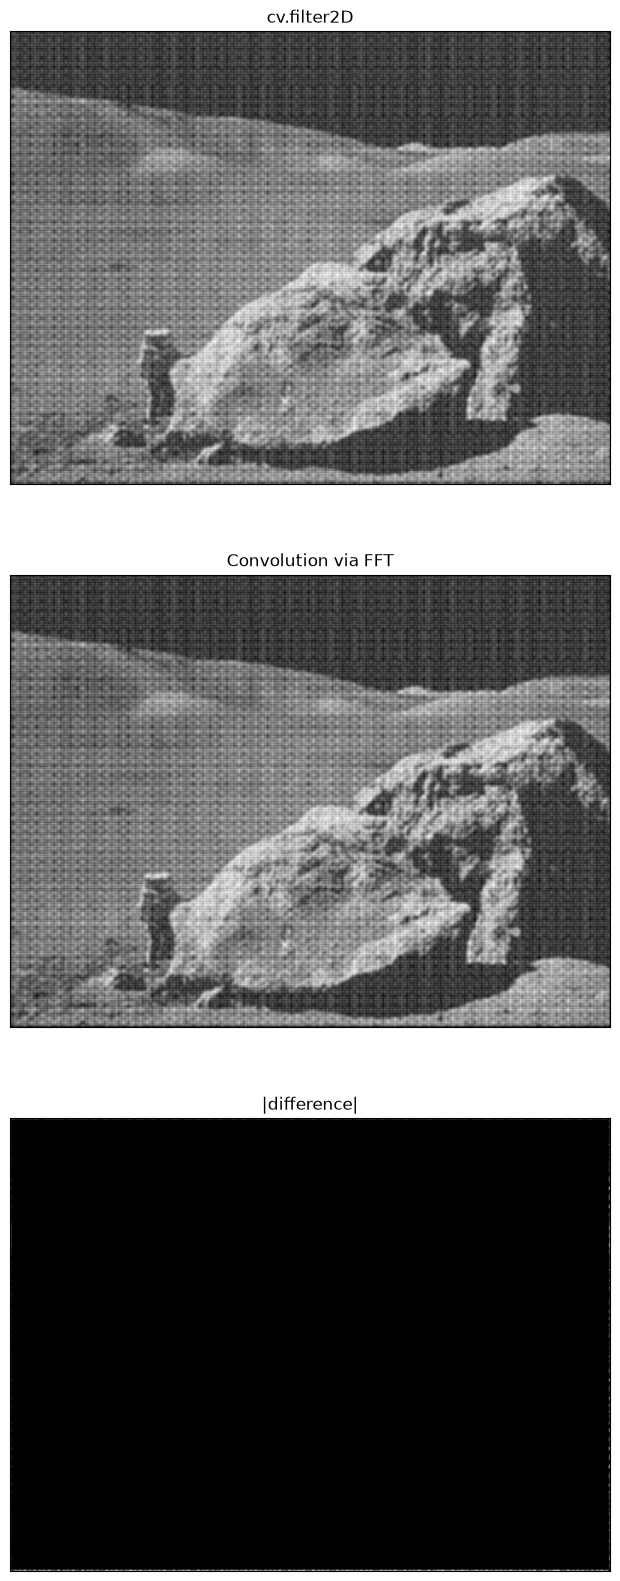

In [9]:
diff = np.abs(res - ref)
print('Max diff (whole image):', diff.max())
print('Max diff (without 5px border):', diff[5:-5, 5:-5].max())

plt.figure(figsize=(8, 20))
plt.subplot(311), plt.imshow(ref, cmap='gray')
plt.title('cv.filter2D'), plt.xticks([]), plt.yticks([])
plt.subplot(312), plt.imshow(res, cmap='gray')
plt.title('Convolution via FFT'), plt.xticks([]), plt.yticks([])
plt.subplot(313), plt.imshow(diff, cmap='gray')
plt.title('|difference|'), plt.xticks([]), plt.yticks([])
plt.show()

## Задание 3. Удаление периодического шума

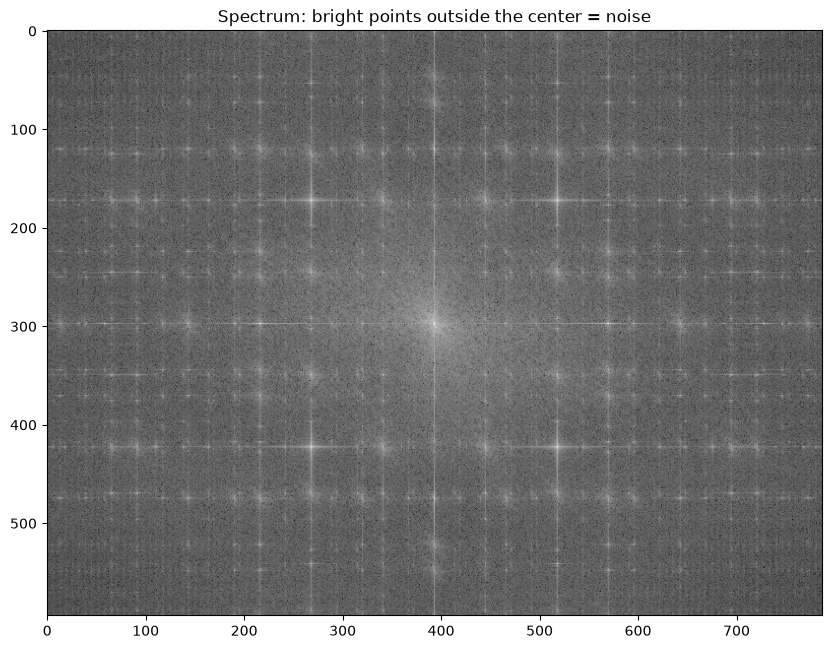

In [10]:
spec = np.fft.fftshift(np.fft.fft2(img))
spec_log = np.log(1 + np.abs(spec))
plt.figure(figsize=(10, 8))
plt.imshow(spec_log, cmap='gray')
plt.title('Spectrum: bright points outside the center = noise')
plt.show()

Masked part of spectrum: 0.105


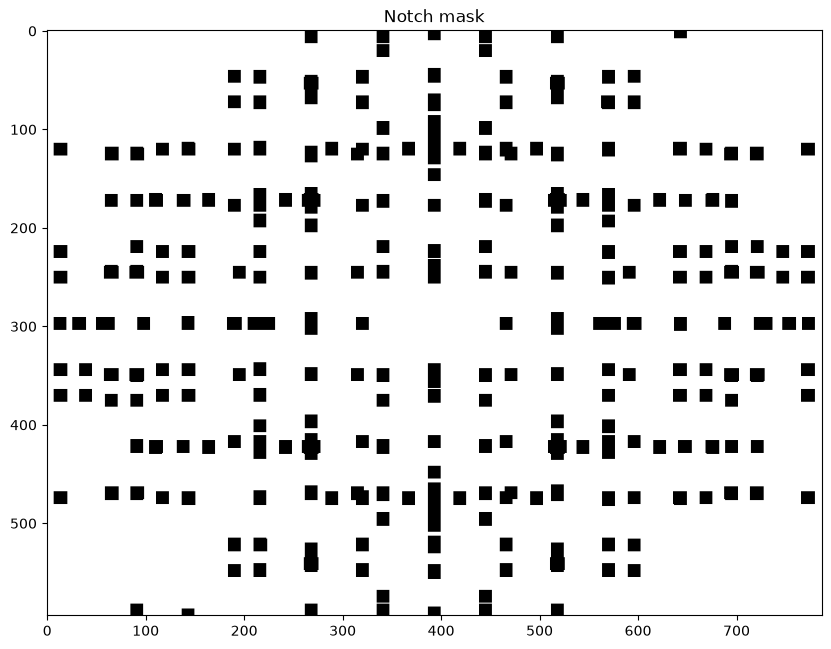

In [11]:
h, w = img.shape
X, Y = np.meshgrid(np.arange(w), np.arange(h))
cx, cy = w // 2, h // 2
r = np.sqrt((X - cx)**2 + (Y - cy)**2)

background = cv.blur(spec_log, (31, 31))
threshold = 3
peaks = (spec_log - background > threshold) & (r > 20)

notch_mask = np.ones((h, w), np.float32)
half = 6
for y, x in np.argwhere(peaks):
    notch_mask[max(0, y - half):y + half + 1, max(0, x - half):x + half + 1] = 0

print('Masked part of spectrum:', round((notch_mask == 0).mean(), 3))
plt.figure(figsize=(10, 8))
plt.imshow(notch_mask, cmap='gray')
plt.title('Notch mask')
plt.show()

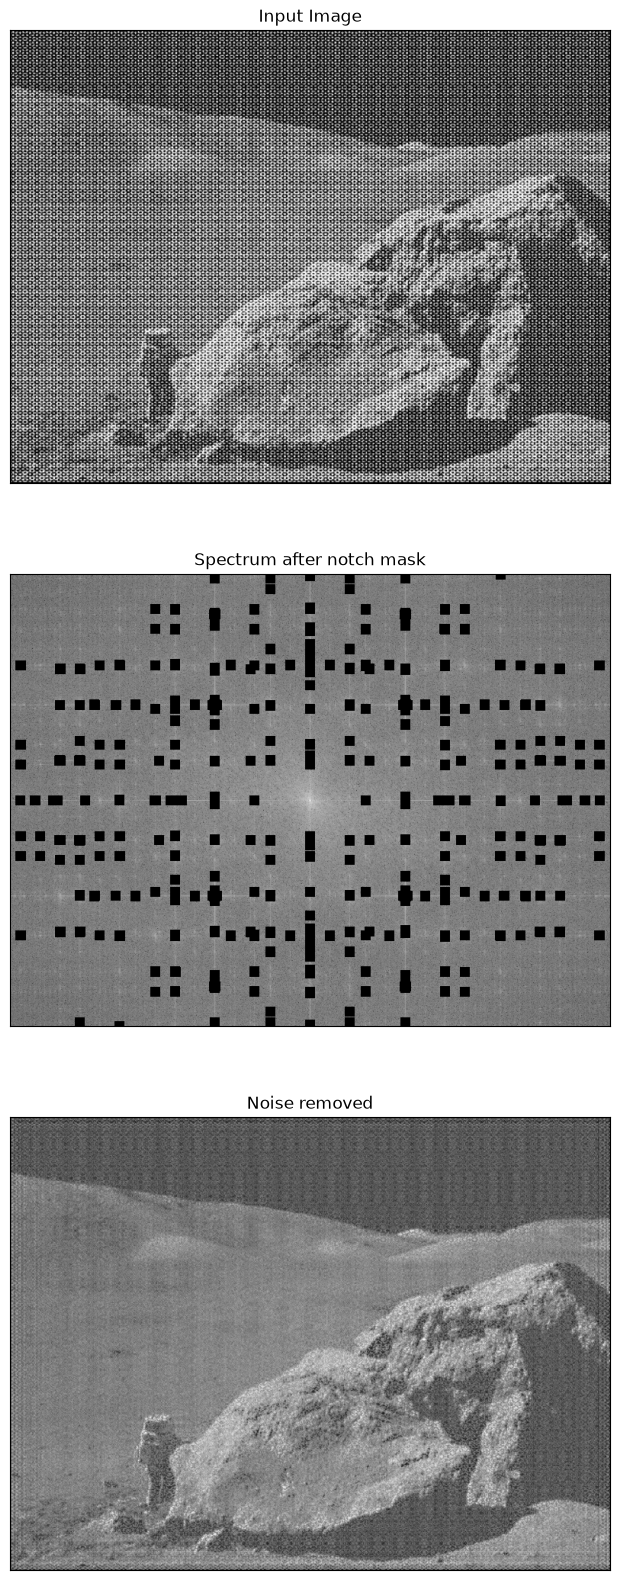

In [12]:
spec_clean = spec * notch_mask
img_clean = np.fft.ifft2(np.fft.ifftshift(spec_clean)).real

plt.figure(figsize=(8, 20))
plt.subplot(311), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(312), plt.imshow(np.log(1 + np.abs(spec_clean)), cmap='gray')
plt.title('Spectrum after notch mask'), plt.xticks([]), plt.yticks([])
plt.subplot(313), plt.imshow(img_clean, cmap='gray')
plt.title('Noise removed'), plt.xticks([]), plt.yticks([])
plt.show()

In [13]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье